# Libraries,Dataset Loading

In [1]:
import warnings 
warnings.filterwarnings("ignore")

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

pd.set_option("display.max_columns", None)

matches = pd.read_csv(r"C:\Users\ELCOT\Downloads\matches.csv")
deliveries = pd.read_csv(r"C:\Users\ELCOT\Downloads\deliveries.csv")

print("Matches Shape:", matches.shape)
print("Deliveries Shape:", deliveries.shape)

Matches Shape: (636, 18)
Deliveries Shape: (150460, 21)


# Dataset information

In [2]:
print("MATCHES COLUMNS")
print(matches.columns.tolist())

print("\nDELIVERIES COLUMNS")
print(deliveries.columns.tolist())

print("\nMATCHES INFO")
matches.info()

print("\nDELIVERIES INFO")
deliveries.info()

MATCHES COLUMNS
['id', 'season', 'city', 'date', 'team1', 'team2', 'toss_winner', 'toss_decision', 'result', 'dl_applied', 'winner', 'win_by_runs', 'win_by_wickets', 'player_of_match', 'venue', 'umpire1', 'umpire2', 'umpire3']

DELIVERIES COLUMNS
['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batsman', 'non_striker', 'bowler', 'is_super_over', 'wide_runs', 'bye_runs', 'legbye_runs', 'noball_runs', 'penalty_runs', 'batsman_runs', 'extra_runs', 'total_runs', 'player_dismissed', 'dismissal_kind', 'fielder']

MATCHES INFO
<class 'pandas.DataFrame'>
RangeIndex: 636 entries, 0 to 635
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               636 non-null    int64  
 1   season           636 non-null    int64  
 2   city             629 non-null    str    
 3   date             636 non-null    str    
 4   team1            636 non-null    str    
 5   team2            636 non-null 

# Missing Values

In [3]:
print("Missing values in MATCHES:")
print(matches.isnull().sum())

print("\nMissing values in DELIVERIES:")
print(deliveries.isnull().sum())

Missing values in MATCHES:
id                   0
season               0
city                 7
date                 0
team1                0
team2                0
toss_winner          0
toss_decision        0
result               0
dl_applied           0
winner               3
win_by_runs          0
win_by_wickets       0
player_of_match      3
venue                0
umpire1              1
umpire2              1
umpire3            636
dtype: int64

Missing values in DELIVERIES:
match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
ball                     0
batsman                  0
non_striker              0
bowler                   0
is_super_over            0
wide_runs                0
bye_runs                 0
legbye_runs              0
noball_runs              0
penalty_runs             0
batsman_runs             0
extra_runs               0
total_runs               0
player_dismissed    143022
di

# Data Cleaning

In [4]:
matches_clean = matches.copy()
deliveries_clean = deliveries.copy()

# Remove duplicate rows 
matches_clean = matches_clean.drop_duplicates()
deliveries_clean = deliveries_clean.drop_duplicates()

#convert data 
matches_clean["date"] = pd.to_datetime(matches_clean["date"])

# Fill categorical mising values
matches_clean["city"] = matches_clean["city"].fillna("Unknown")
matches_clean["winner"] = matches_clean["winner"].fillna("Unknown")
matches_clean["player_of_match"] = matches_clean["player_of_match"].fillna("Unknown")

matches_clean["umpire1"] = matches_clean["umpire1"].fillna("Unknown")
matches_clean["umpire2"] = matches_clean["umpire2"].fillna("Unknown")

print("Cleaning completed.")
print("Duplicate match rows:",matches.duplicated().sum())
print("Duplicate delivery rows:",deliveries.duplicated().sum())


Cleaning completed.
Duplicate match rows: 0
Duplicate delivery rows: 1


# Season Wise Match Analysis

season
2008    58
2009    57
2010    60
2011    73
2012    74
2013    76
2014    60
2015    59
2016    60
2017    59
dtype: int64


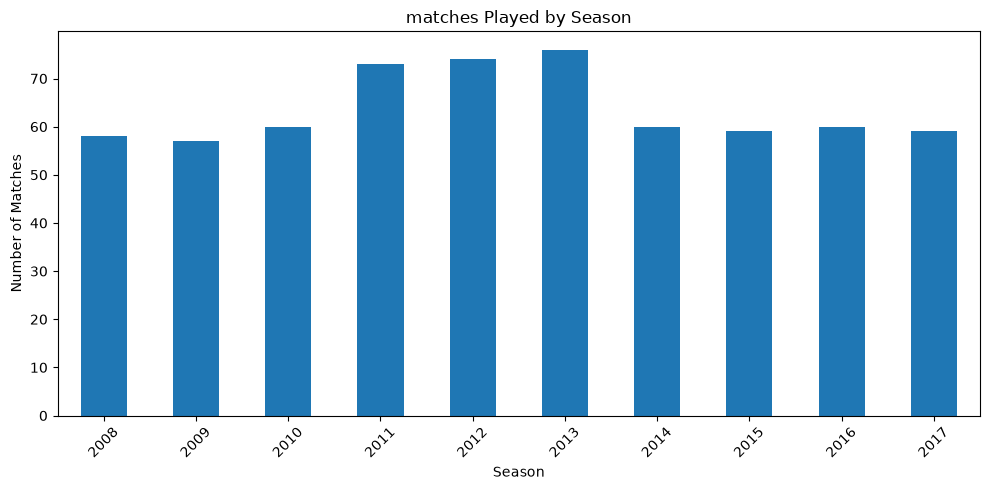

In [5]:
season_matches = matches_clean.groupby("season").size()

print(season_matches)

plt.figure(figsize=(10,5))
season_matches.plot(kind="bar")
plt.title("matches Played by Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

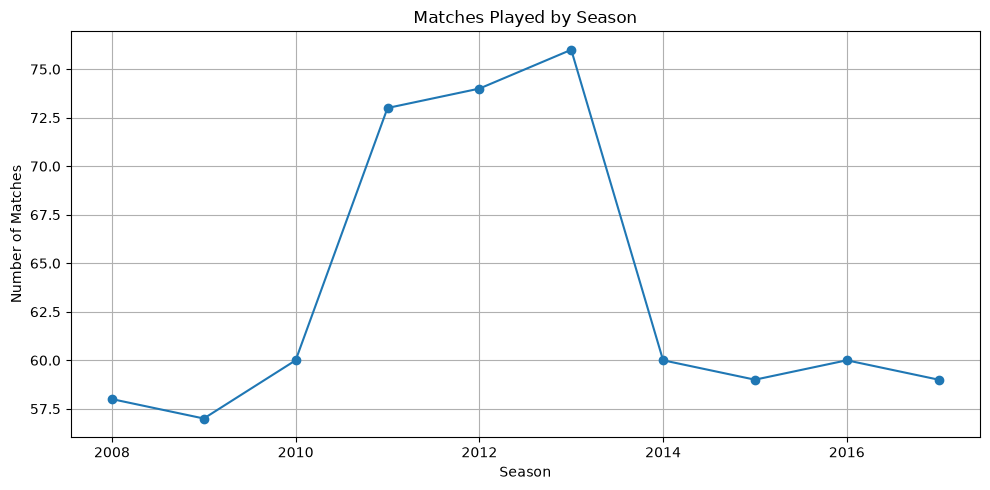

In [6]:
# LINE GRAPH - SEASON WISE MATCHES

season_matches = matches_clean.groupby("season").size()

plt.figure(figsize=(10,5))

plt.plot(
    season_matches.index,
    season_matches.values,
    marker="o"
)

plt.title("Matches Played by Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")

plt.grid(True)
plt.tight_layout()
plt.show()

# Team Performance Analysis

Top teams by number of wins:
winner
Mumbai Indians                 92
Chennai Super Kings            79
Kolkata Knight Riders          77
Royal Challengers Bangalore    73
Kings XI Punjab                70
Rajasthan Royals               63
Delhi Daredevils               62
Sunrisers Hyderabad            42
Deccan Chargers                29
Gujarat Lions                  13
Name: count, dtype: int64


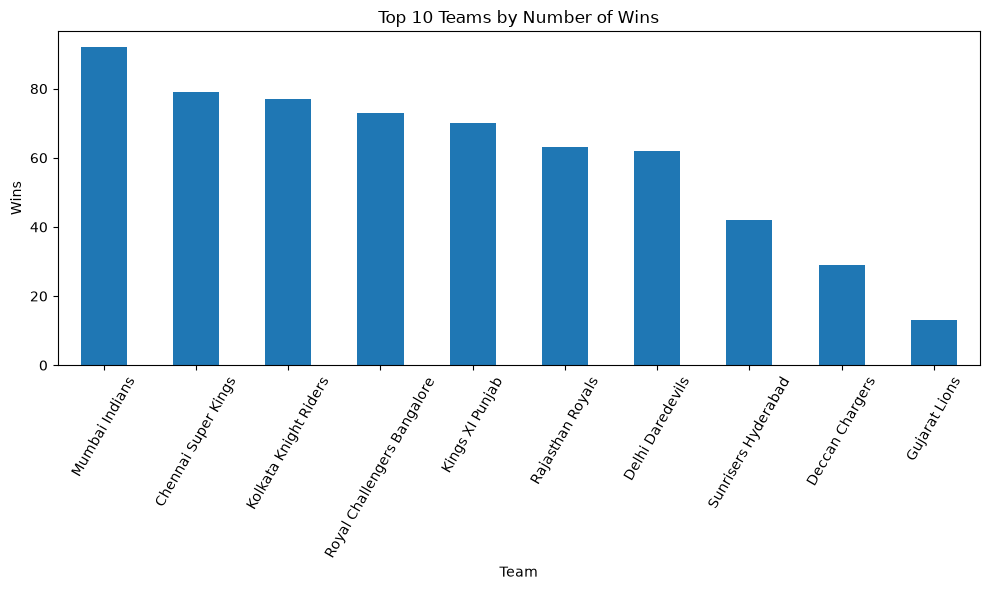

In [7]:
team_wins = matches_clean[matches_clean["winner"] != "Unknown"]["winner"].value_counts()

print("Top teams by number of wins:")
print(team_wins.head(10))

plt.figure(figsize=(10,6))
team_wins.head(10).plot(kind="bar")
plt.title("Top 10 Teams by Number of Wins")
plt.xlabel("Team")
plt.ylabel("Wins")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Toss Analysis

Toss decisions:
toss_decision
field    363
bat      273
Name: count, dtype: int64

Toss winner also won the match: 51.1 %


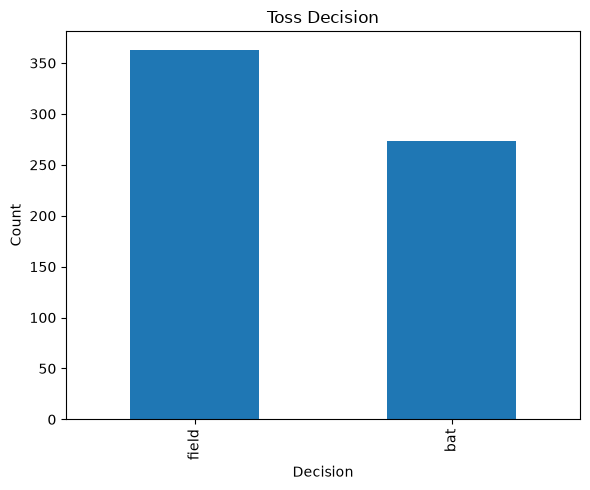

In [8]:
print("Toss decisions:")
print(matches_clean["toss_decision"].value_counts())

toss_match_winner = (matches_clean["toss_winner"] == matches_clean["winner"]).mean() * 100

print("\nToss winner also won the match:",round(toss_match_winner, 2), "%")

plt.figure(figsize=(6,5))
matches_clean["toss_decision"].value_counts().plot(kind="bar")
plt.title("Toss Decision")
plt.xlabel("Decision")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Top Wicket Takers

player_dismissed
SK Raina        134
G Gambhir       131
RG Sharma       129
RV Uthappa      128
V Kohli         118
KD Karthik      117
S Dhawan        109
PA Patel        107
Yuvraj Singh    101
DA Warner       100
dtype: int64


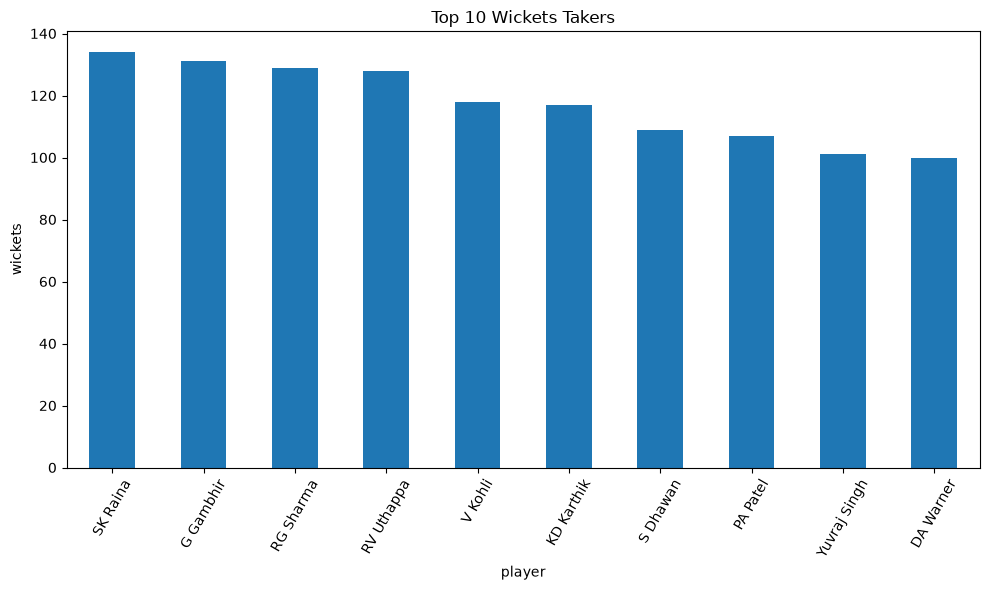

In [9]:
valid_dismissals = deliveries_clean[deliveries_clean["player_dismissed"].notna()]

top_bowlers = (
    valid_dismissals
    .groupby("player_dismissed")
    .size()
    .sort_values(ascending=False)
    .head(10)   
)

print(top_bowlers)

plt.figure(figsize=(10,6))
top_bowlers.plot(kind="bar")
plt.title("Top 10 Wickets Takers")
plt.xlabel("player")
plt.ylabel("wickets")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# 200+ Runs Analysis

In [11]:
innings_score = (deliveries_clean.groupby(["match_id", "inning"])["total_runs"].sum())

high_scoring = innings_score[innings_score >= 200]

print("Number of team innings with 200+ runs:",len(high_scoring))

print("\nHighest scores:")
print(high_scoring.sort_values(ascending=False).head(10))

Number of team innings with 200+ runs: 67

Highest scores:
match_id  inning
411       1         263
620       1         248
206       1         246
61        1         240
562       1         235
296       1         232
486       1         231
259       1         231
50        1         230
580       1         227
Name: total_runs, dtype: int64


# Super Over Analysis

In [12]:
super_over = deliveries_clean[deliveries_clean["is_super_over"] == 1]

print("Super-over deliveries:", len(super_over))

super_over_matches = super_over["match_id"].nunique()

print("Matches with super over:",super_over_matches)

print(super_over[["match_id", "inning", "batting_team","bowling_team"]].drop_duplicates())

Super-over deliveries: 81
Matches with super over: 7
        match_id  inning                 batting_team  \
8092          34       3               Mumbai Indians   
8097          34       4                Gujarat Lions   
29279        126       3        Kolkata Knight Riders   
29286        126       4             Rajasthan Royals   
44819        190       3          Chennai Super Kings   
44824        190       4              Kings XI Punjab   
91904        388       3          Sunrisers Hyderabad   
91911        388       4  Royal Challengers Bangalore   
95073        401       3  Royal Challengers Bangalore   
95079        401       4             Delhi Daredevils   
112912       476       3        Kolkata Knight Riders   
112918       476       4             Rajasthan Royals   
127359       536       3              Kings XI Punjab   
127366       536       4             Rajasthan Royals   

                       bowling_team  
8092                  Gujarat Lions  
8097           

# Umpire Analysis 

HDPK Dharmasena          87
S Ravi                   85
AK Chaudhary             58
C Shamshuddin            56
SJA Taufel               55
M Erasmus                54
Asad Rauf                51
BR Doctrove              42
CK Nandan                41
RE Koertzen              41
VA Kulkarni              39
Aleem Dar                38
RJ Tucker                38
BF Bowden                37
BNJ Oxenford             32
SK Tarapore              31
S Asnani                 30
RB Tiffin                30
DJ Harper                27
AM Saheba                26
NJ Llong                 25
CB Gaffaney              24
K Hariharan              21
Nitin Menon              19
RK Illingworth           19
BG Jerling               17
SS Hazare                17
JD Cloete                17
A Nand Kishore           16
S Das                    15
K Srinath                15
IL Howell                14
SL Shastri               14
AY Dandekar              13
MR Benson                12
KN Ananthapadmanabha

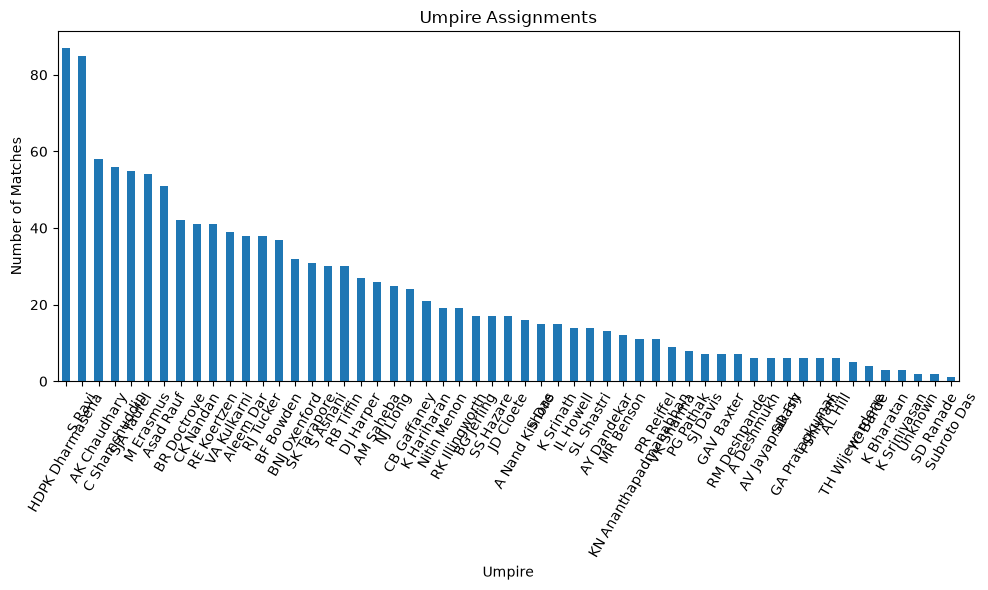

In [13]:
umpire = pd.concat([matches_clean["umpire1"],matches_clean["umpire2"],matches_clean["umpire3"]])

umpire_counts = (umpire
    .dropna()
    .value_counts()
)

print(umpire_counts)

plt.figure(figsize=(10,6))

umpire_counts.plot(kind="bar")

plt.title("Umpire Assignments")
plt.xlabel("Umpire")
plt.ylabel("Number of Matches")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Player of the Match

player_of_match
CH Gayle          18
YK Pathan         16
DA Warner         15
AB de Villiers    15
SK Raina          14
RG Sharma         14
MS Dhoni          13
G Gambhir         13
MEK Hussey        12
AM Rahane         12
Name: count, dtype: int64


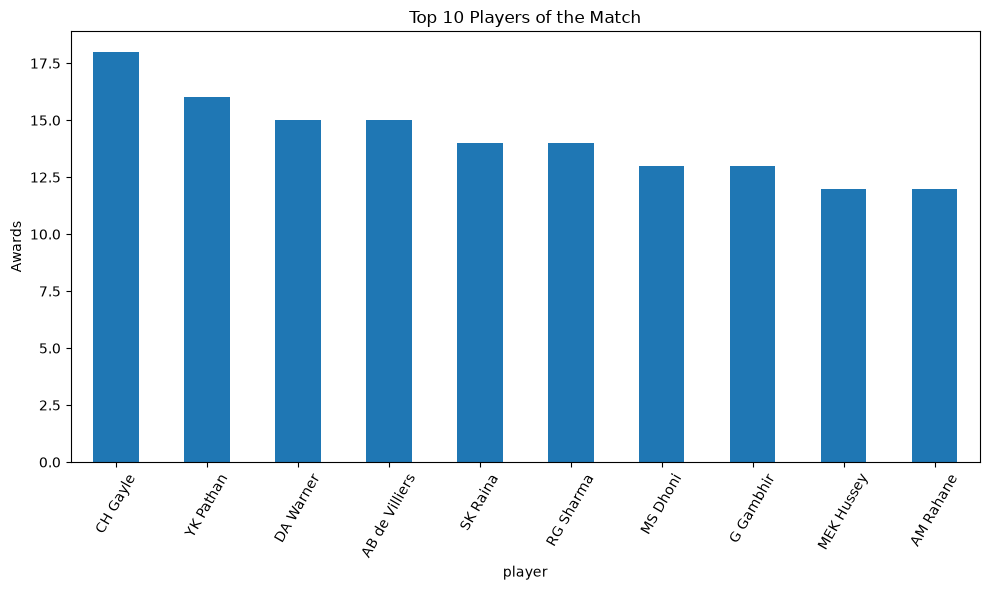

In [14]:
pom = (matches_clean[matches_clean["player_of_match"] != "Unknown"]["player_of_match"].value_counts().head(10))

print(pom)

plt.figure(figsize=(10,6))
pom.plot(kind="bar")
plt.title("Top 10 Players of the Match")
plt.xlabel("player")
plt.ylabel("Awards")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Orange Cap - Season Wise

In [15]:
bat_season = (deliveries_clean.merge(matches_clean[["id", "season"]],left_on="match_id",right_on="id")
             .groupby(["season", "batsman"])["batsman_runs"]
             .sum()
             .reset_index()
             )

orange_cap = bat_season.loc[bat_season.groupby("season")["batsman_runs"].idxmax()].sort_values("season")

print(orange_cap)

      season       batsman  batsman_runs
115     2008      SE Marsh           616
229     2009     ML Hayden           572
446     2010  SR Tendulkar           617
502     2011      CH Gayle           608
684     2012      CH Gayle           733
910     2013    MEK Hussey           733
1088    2014    RV Uthappa           660
1148    2015     DA Warner           562
1383    2016       V Kohli           973
1422    2017     DA Warner           641


# Purple Cap - Season-Wise 

In [16]:
wicket_data = deliveries_clean[deliveries_clean["player_dismissed"].notna()].merge(matches_clean[["id", "season"]],left_on="match_id",right_on="id")

wicket_season = (wicket_data
                .groupby(["season", "bowler"])
                .size()
                .reset_index(name="wickets")
                )

purple_cap = wicket_season.loc[wicket_season.groupby("season")["wickets"].idxmax()].sort_values("season")

print(purple_cap)

     season         bowler  wickets
77     2008  Sohail Tanvir       24
157    2009       RP Singh       26
248    2010        PP Ojha       22
375    2011     SL Malinga       30
447    2012       M Morkel       30
519    2013       DJ Bravo       34
651    2014      MM Sharma       26
709    2015       DJ Bravo       28
792    2016        B Kumar       24
880    2017        B Kumar       28


# Player Comparison

In [17]:
players = ["V Kohli", "SK Raina"]

player_runs = (deliveries_clean[deliveries_clean["batsman"].isin(players)].groupby("batsman")["batsman_runs"].sum())

player_dismissals = (deliveries_clean[deliveries_clean["player_dismissed"].isin(players)].groupby("player_dismissed").size())

comparison = pd.DataFrame({"Runs":player_runs,"Dismissals":player_dismissals})

print(comparison)

          Runs  Dismissals
SK Raina  4548         134
V Kohli   4423         118


# Team Comparison

In [7]:
team_wins = matches_clean[matches_clean["winner"] != "Unknown"]["winner"].value_counts()
team_summary = pd.DataFrame({"Wins": team_wins})

team_summary["Win Percentage"] = (team_summary["Wins"] / matches_clean["team1"].value_counts().add(matches_clean["team2"].value_counts(),fill_value=0) * 100)
                                  
team_summary = team_summary.sort_values("Wins", ascending=False)

print(team_summary.head(10))
                                  

                             Wins  Win Percentage
winner                                           
Mumbai Indians                 92       58.598726
Chennai Super Kings            79       60.305344
Kolkata Knight Riders          77       52.027027
Royal Challengers Bangalore    73       48.026316
Kings XI Punjab                70       47.297297
Rajasthan Royals               63       53.389831
Delhi Daredevils               62       42.176871
Sunrisers Hyderabad            42       55.263158
Deccan Chargers                29       38.666667
Gujarat Lions                  13       43.333333


# Season Winner

In [8]:
season_winner = (matches_clean[matches_clean["winner"] != "Unknown"]
                .groupby("season")["winner"]
                .agg(lambda x: x.value_counts().index[0])
                )

print(season_winner)

season
2008         Rajasthan Royals
2009         Delhi Daredevils
2010           Mumbai Indians
2011      Chennai Super Kings
2012    Kolkata Knight Riders
2013           Mumbai Indians
2014          Kings XI Punjab
2015      Chennai Super Kings
2016      Sunrisers Hyderabad
2017           Mumbai Indians
Name: winner, dtype: str


# Machine Learning - Feature Engineering

In [15]:
model_df = matches[matches["winner"].isin(pd.unique(pd.concat([matches["team1"],matches["team2"]])))].copy()

features = ["season","city","team1","team2","toss_winner","toss_decision","venue","dl_applied"]

x = model_df[features]
y = model_df["winner"]

categorical_features = ["city","team1","team2","toss_winner","toss_decision"]

numeric_features = ["season","dl_applied"]

preprocessor = ColumnTransformer([("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical_features),("num",SimpleImputer(strategy="median"),numeric_features)])

X = model_df[features]
y= model_df["winner"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 506
Testing rows: 127


# Logistic Regression

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline(steps=[('preprocessor', preprocessor),('model',LogisticRegression(
    max_iter=1000,
    random_state=42))])

lr_pipeline.fit(X_train, y_train)

y_pred_lr = lr_pipeline.predict(X_test)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

Logistic Regression Accuracy: 53.54 %

Classification Report:
                             precision    recall  f1-score   support

        Chennai Super Kings       0.57      0.55      0.56        22
            Deccan Chargers       0.00      0.00      0.00         6
           Delhi Daredevils       0.50      0.67      0.57         9
              Gujarat Lions       0.50      0.33      0.40         3
            Kings XI Punjab       0.43      0.38      0.40        16
       Kochi Tuskers Kerala       0.00      0.00      0.00         1
      Kolkata Knight Riders       0.70      0.74      0.72        19
             Mumbai Indians       0.62      0.81      0.70        16
              Pune Warriors       0.00      0.00      0.00         2
           Rajasthan Royals       0.25      0.25      0.25         8
     Rising Pune Supergiant       1.00      0.33      0.50         3
Royal Challengers Bangalore       0.56      0.62      0.59        16
        Sunrisers Hyderabad       0.50  

# Random Forest

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 14.17 %


# Model Accuracy Comparsion

                 Model  Accuracy
0  Logistic Regression  0.535433
1        Random Forest  0.535433


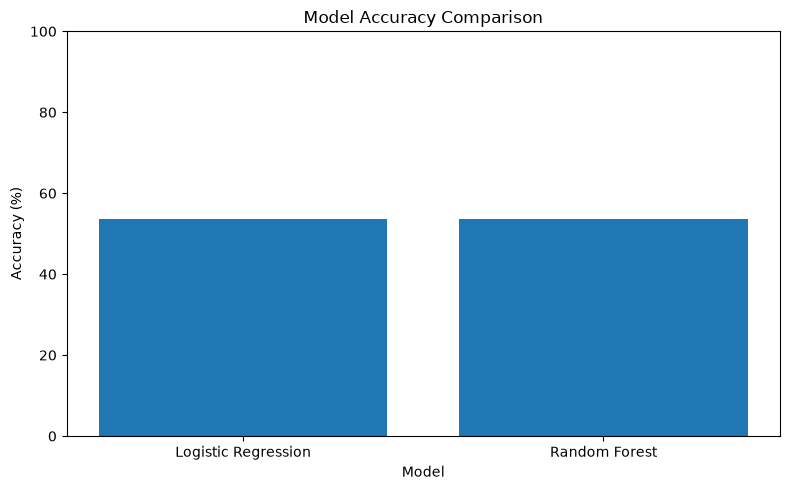

In [20]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        acc_lr,
        acc_rf
    ]
})

print(model_results)

plt.figure(figsize=(8,5))

plt.bar(
    model_results["Model"],
    model_results["Accuracy"] * 100
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0,100)

plt.tight_layout()
plt.show()

# Match Winner Prediction

In [18]:
sample = X_test.iloc[[0]].copy()
actual = y_test.iloc[0]

pred_lr = logistic_model.predict(sample)[0]
pred_rf = rf_model.predict(sample)[0]

print("Sample Match Information:")
print(sample)

print("\nActual Winner:", actual)
print("Logistic Regression Prediction:", pred_lr)
print("Random Forest Prediction:", pred_rf)

Sample Match Information:
    season  dl_applied
70    2008           0

Actual Winner: Chennai Super Kings
Logistic Regression Prediction: Mumbai Indians
Random Forest Prediction: Rajasthan Royals


# Confusion Matrix

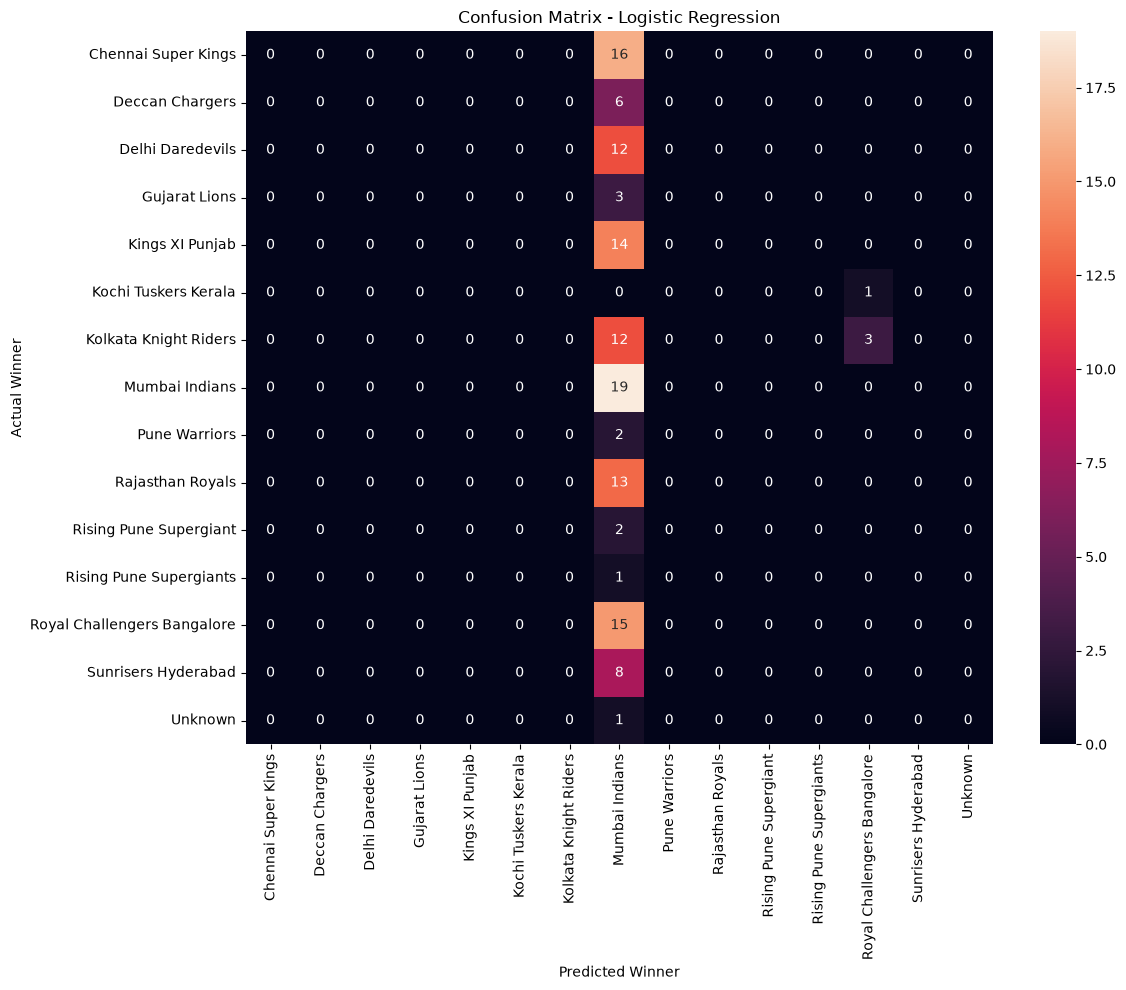

Best Model: Logistic Regression


In [19]:
best_pred = (
    y_pred_lr
    if acc_lr >= acc_rf
    else y_pred_rf
)

best_model_name = (
    "Logistic Regression"
    if acc_lr >= acc_rf
    else "Random Forest"
)

labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    best_pred,
    labels=labels
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted Winner")
plt.ylabel("Actual Winner")

plt.tight_layout()
plt.show()

print("Best Model:", best_model_name)

# Final Project insights

In [20]:
print("========== FINAL PROJECT INSIGHTS ==========")

print(
    "1. Dataset contains",
    matches_clean.shape[0],
    "matches and",
    deliveries_clean.shape[0],
    "ball-by-ball records."
)

print(
    "2. Mumbai Indians has the highest number of wins "
    "in this dataset."
)

print(
    "3. Top batsmen and wicket-taking players "
    "were identified."
)

print(
    "4. There are 67 team innings with 200+ runs."
)

print(
    "5. There are 7 matches involving Super Over."
)

print(
    "6. Umpire assignment frequency was analysed."
)

print(
    "7. Season-wise Orange Cap-style run leaders "
    "were identified."
)

print(
    "8. Season-wise Purple Cap-style wicket leaders "
    "were identified."
)

print(
    "9. Player and team comparison was performed."
)

print(
    "10. Match winner prediction was performed "
    "using pre-match features."
)

print(
    f"11. Logistic Regression Accuracy: "
    f"{acc_lr*100:.2f}%"
)

print(
    f"12. Random Forest Accuracy: "
    f"{acc_rf*100:.2f}%"
)

print("============================================")

========== FINAL PROJECT INSIGHTS ==========
1. Dataset contains 636 matches and 150459 ball-by-ball records.
2. Mumbai Indians has the highest number of wins in this dataset.
3. Top batsmen and wicket-taking players were identified.
4. There are 67 team innings with 200+ runs.
5. There are 7 matches involving Super Over.
6. Umpire assignment frequency was analysed.
7. Season-wise Orange Cap-style run leaders were identified.
8. Season-wise Purple Cap-style wicket leaders were identified.
9. Player and team comparison was performed.
10. Match winner prediction was performed using pre-match features.
11. Logistic Regression Accuracy: 14.84%
12. Random Forest Accuracy: 10.16%
